# Adaptive-GVAR: experiments

Inspect a saved checkpoint. No training or checkpoint writes.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "models/GVAR/gvar.py").exists())
sys.path.insert(0, str(ROOT / "models"))
sys.path.insert(0, str(ROOT / "models/GVAR"))

from common import Windows, load_session, summarize
from data import load_graph, shift_operator, trials
from temporal_adaptive_gvar import AdaptiveGVAR, correction_statistics


In [2]:
dataset = ROOT / "processed/session_4_7_proximity_v1926"
checkpoint = ROOT / "models/GVAR/checkpoints/adaptive_gvar_sparsemax/best.pt"


In [3]:
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
if saved["model_type"] != "temporal_adaptive_gvar_v1":
    raise ValueError("Unexpected checkpoint implementation")
if saved["preprocessing"] != {"log_transform": True, "val_frac": 0.15, "test_frac": 0.15}:
    raise ValueError("Unexpected checkpoint preprocessing")
config = dict(saved["config"])
config.setdefault("activation", "softmax")
config.setdefault("tau", 1.0)
P = config["P"]
seed = saved.get("training", {}).get("seed", 123)
batch_size = saved.get("training", {}).get("batch_size", 8)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
data = load_session(str(dataset), True, 0.15, 0.15, False)
n_nodes = data["X"].shape[1]
edges, weights = load_graph(data["data_dir"], n_nodes)
A = shift_operator(edges, weights, n_nodes, kind="mean")
torch.testing.assert_close(saved["state_dict"]["S"], A.to_dense(), rtol=0, atol=0)
model = AdaptiveGVAR(A, **config).to(device)
model.load_state_dict(saved["state_dict"])
model.eval()
val_windows = ConcatDataset([
    Windows(x.unfold(0, P + 1, 1).permute(0, 2, 1), None, P)
    for x in trials(data, "val") if len(x) > P
])
val_loader = DataLoader(val_windows, batch_size=batch_size, shuffle=False)
run_prefix = f"{checkpoint.stem}_{config['activation']}_tau{config['tau']:g}"
results_dir = ROOT / "models/GVAR/runs" / checkpoint.parent.name
results_dir.mkdir(parents=True, exist_ok=True)


## Correction graph

Rows: targets; columns: sources. Statistics use 32 validation windows.


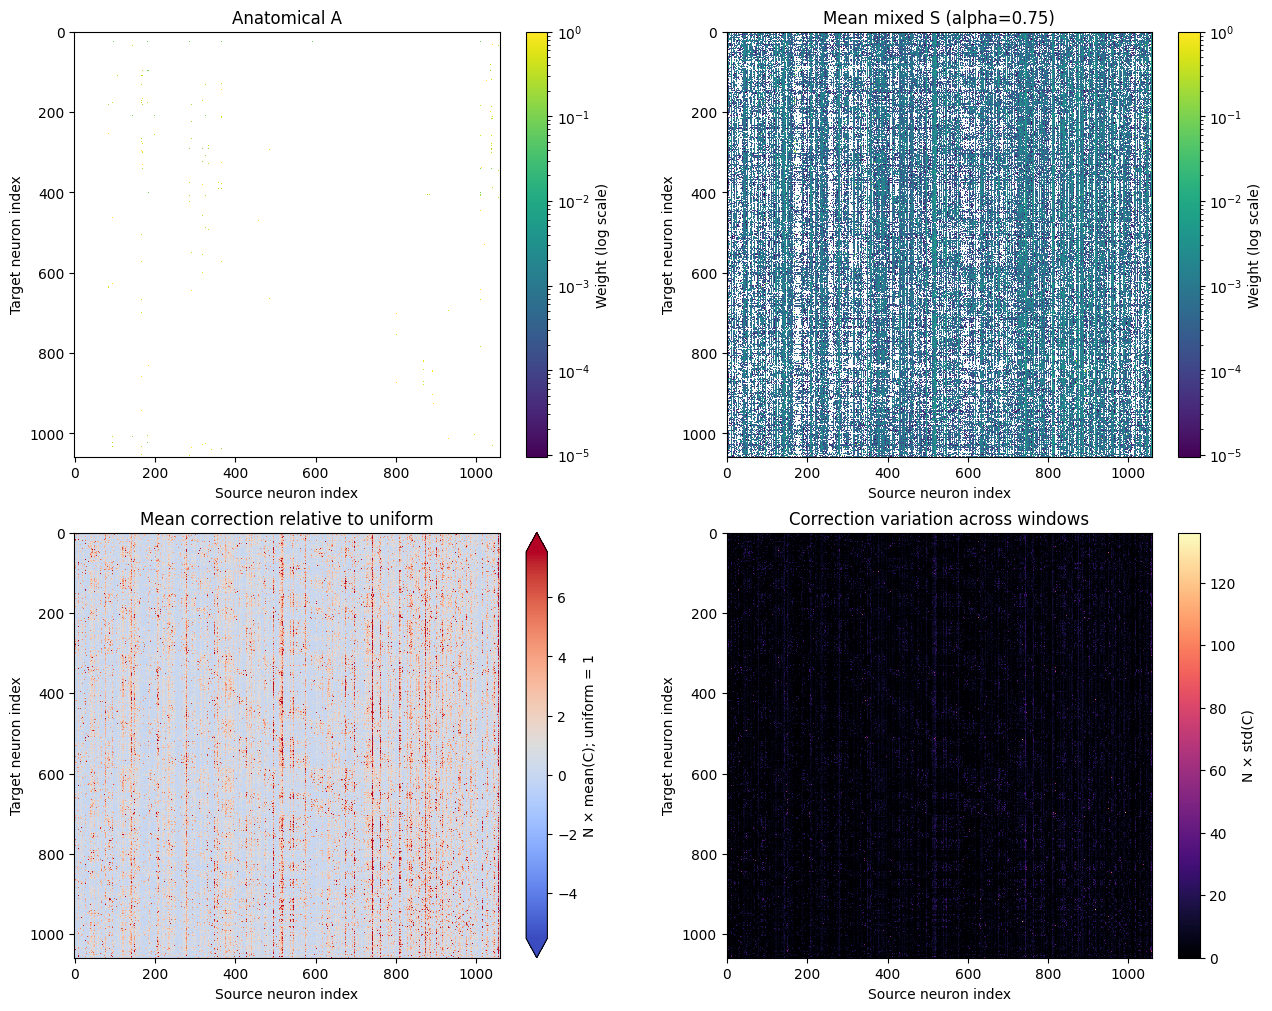

,Zeros (%),Inputs / target,Single-input rows (%),Row entropy
0,94.5908,57.2834,0.0,0.5065


In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm

model.eval()
graph_indices = np.linspace(0, len(val_windows) - 1, min(32, len(val_windows)), dtype=int)
graph_batches = []
with torch.no_grad():
    for indices in tqdm(np.array_split(graph_indices, max(1, (len(graph_indices) + batch_size - 1) // batch_size)),
                        desc="Inspect graphs", unit="batch"):
        past = torch.stack([val_windows[int(i)][0] for i in indices]).to(device)
        graph_batches.append(model.graph_learner(past).cpu())
corrections = torch.cat(graph_batches)
mean_C = corrections.mean(0)
mean_S = (1 - model.alpha) * model.A.cpu() + model.alpha * mean_C
anatomy = model.A.cpu()
relative_C = mean_C * n_nodes
relative_std = corrections.std(0, unbiased=False) * n_nodes

fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
log_cmap = plt.get_cmap("viridis").copy()
log_cmap.set_bad("white")
log_scale = LogNorm(vmin=0.01 / n_nodes, vmax=max(1., float(mean_S.max())))
for ax, matrix, title in [(axes[0, 0], anatomy, "Anatomical A"),
                          (axes[0, 1], mean_S, f"Mean mixed S (alpha={model.alpha:g})")]:
    im = ax.imshow(np.ma.masked_less_equal(matrix.numpy(), 0), cmap=log_cmap,
                   norm=log_scale, interpolation="nearest", rasterized=True)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="Weight (log scale)")
limit = max(0.01, float(torch.quantile((relative_C - 1).abs().flatten(), 0.99)))
im = axes[1, 0].imshow(relative_C.numpy(), cmap="coolwarm",
                       norm=TwoSlopeNorm(vmin=1-limit, vcenter=1, vmax=1+limit),
                       interpolation="nearest", rasterized=True)
axes[1, 0].set_title("Mean correction relative to uniform")
fig.colorbar(im, ax=axes[1, 0], label="N × mean(C); uniform = 1", extend="both")
im = axes[1, 1].imshow(relative_std.numpy(), cmap="magma", interpolation="nearest", rasterized=True)
axes[1, 1].set_title("Correction variation across windows")
fig.colorbar(im, ax=axes[1, 1], label="N × std(C)")
for ax in axes.flat:
    ax.set(xlabel="Source neuron index", ylabel="Target neuron index")
plt.show()

entropy = -(corrections * corrections.clamp_min(1e-12).log()).sum(-1).mean() / np.log(n_nodes)
graph_summary = pd.DataFrame([{
    "Zeros (%)": 100 * correction_statistics(corrections)["zero_fraction"],
    "Inputs / target": correction_statistics(corrections)["mean_nonzero_incoming_edges"],
    "Single-input rows (%)": 100 * correction_statistics(corrections)["singleton_row_fraction"],
    "Row entropy": entropy.item(),
}])
display(graph_summary.round(4))
fig.savefig(results_dir / f"{run_prefix}_graph_heatmaps.png", dpi=150)


## Source attention

Column sums versus key lengths; 128-neuron query sample per window.


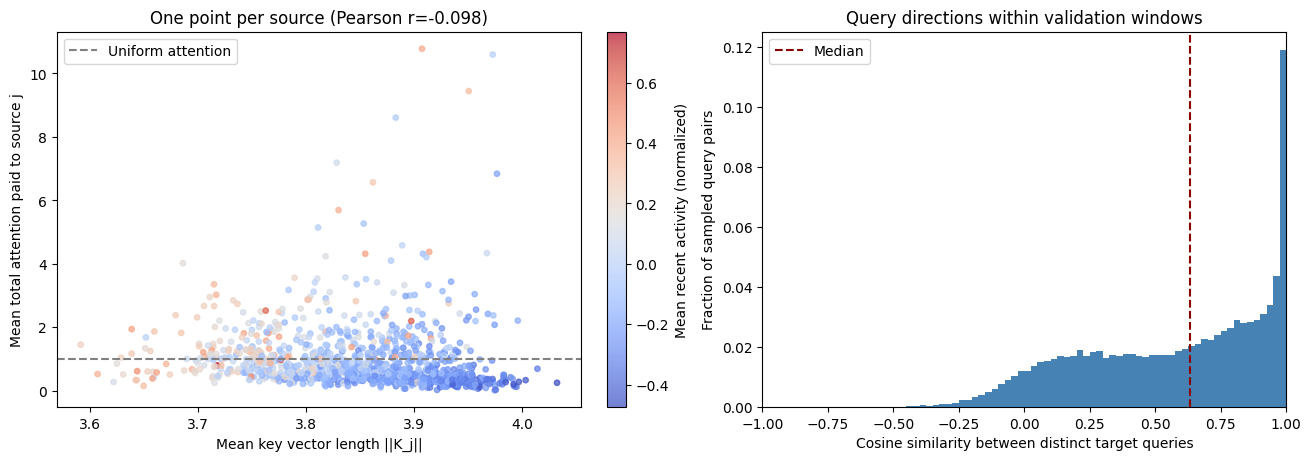

,Value
Key length vs attention (r),-0.0981
Query cosine (median),0.6314
Query pairs > 0.95 (%),16.2951


In [5]:
import matplotlib.pyplot as plt

embedding_indices = np.linspace(0, len(val_windows) - 1, min(32, len(val_windows)), dtype=int)
query_neurons = np.random.default_rng(seed).choice(n_nodes, min(n_nodes, 128), replace=False)
query_neurons = torch.tensor(query_neurons, device=device)
pair_indices = torch.triu_indices(len(query_neurons), len(query_neurons), offset=1, device=device)
key_norm_batches, source_attention_batches, activity_batches, query_cosine_batches = [], [], [], []
embedding_original_training = model.training
try:
    model.eval()
    with torch.no_grad():
        for indices in tqdm(np.array_split(embedding_indices,
                             max(1, (len(embedding_indices) + batch_size - 1) // batch_size)),
                            desc="Embedding diagnostics", unit="batch"):
            past = torch.stack([val_windows[int(i)][0] for i in indices]).to(device)
            B, T, N = past.shape
            _, hidden = model.graph_learner.encoder(past.transpose(1, 2).reshape(B * N, T, 1))
            H = hidden[0].reshape(B, N, -1)
            Q = model.graph_learner.W_q(H)
            K_embeddings = model.graph_learner.W_k(H)
            C = model.graph_learner.normalize_scores(
                Q @ K_embeddings.transpose(-1, -2) / Q.shape[-1] ** 0.5)
            key_norm_batches.append(K_embeddings.norm(dim=-1).cpu())
            source_attention_batches.append(C.sum(dim=-2).cpu())  # Sum targets, keep sources.
            activity_batches.append(past.mean(dim=1).cpu())
            unit_queries = F.normalize(Q[:, query_neurons], dim=-1)
            cosine = unit_queries @ unit_queries.transpose(-1, -2)
            query_cosine_batches.append(cosine[:, pair_indices[0], pair_indices[1]].cpu().flatten())
finally:
    model.train(embedding_original_training)

embedding_table = pd.DataFrame({
    "neuron_index": np.arange(n_nodes),
    "mean_key_norm": torch.cat(key_norm_batches).mean(0).numpy(),
    "mean_source_attention": torch.cat(source_attention_batches).mean(0).numpy(),
    "mean_recent_activity": torch.cat(activity_batches).mean(0).numpy(),
})
query_cosines = torch.cat(query_cosine_batches).clamp(-1, 1).numpy()
key_attention_correlation = embedding_table[["mean_key_norm", "mean_source_attention"]].corr().iloc[0, 1]

fig_embeddings, axes_embeddings = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
points = axes_embeddings[0].scatter(
    embedding_table.mean_key_norm, embedding_table.mean_source_attention,
    c=embedding_table.mean_recent_activity, cmap="coolwarm", s=15, alpha=0.7)
axes_embeddings[0].axhline(1, color="grey", linestyle="--", label="Uniform attention")
axes_embeddings[0].set(xlabel="Mean key vector length ||K_j||",
                       ylabel="Mean total attention paid to source j",
                       title=f"One point per source (Pearson r={key_attention_correlation:.3f})")
axes_embeddings[0].legend()
fig_embeddings.colorbar(points, ax=axes_embeddings[0], label="Mean recent activity (normalized)")
axes_embeddings[1].hist(query_cosines, bins=np.linspace(-1, 1, 81),
                        weights=np.full(len(query_cosines), 1 / len(query_cosines)), color="steelblue")
axes_embeddings[1].axvline(float(np.median(query_cosines)), color="darkred", linestyle="--", label="Median")
axes_embeddings[1].set(xlabel="Cosine similarity between distinct target queries",
                       ylabel="Fraction of sampled query pairs", xlim=(-1, 1),
                       title="Query directions within validation windows")
axes_embeddings[1].legend()
plt.show()

embedding_summary = pd.Series({
    "Key length vs attention (r)": key_attention_correlation,
    "Query cosine (median)": float(np.median(query_cosines)),
    "Query pairs > 0.95 (%)": 100 * float((query_cosines > 0.95).mean()),
}, name="Value")
display(embedding_summary.round(4).to_frame())
embedding_results_dir = results_dir
embedding_results_dir.mkdir(parents=True, exist_ok=True)
embedding_table.to_csv(embedding_results_dir / f"{run_prefix}_embedding_diagnostics.csv", index=False)
fig_embeddings.savefig(embedding_results_dir / f"{run_prefix}_embedding_diagnostics.png", dpi=150)


## H, Q and K

Cosine similarities for the same neuron pairs and windows.


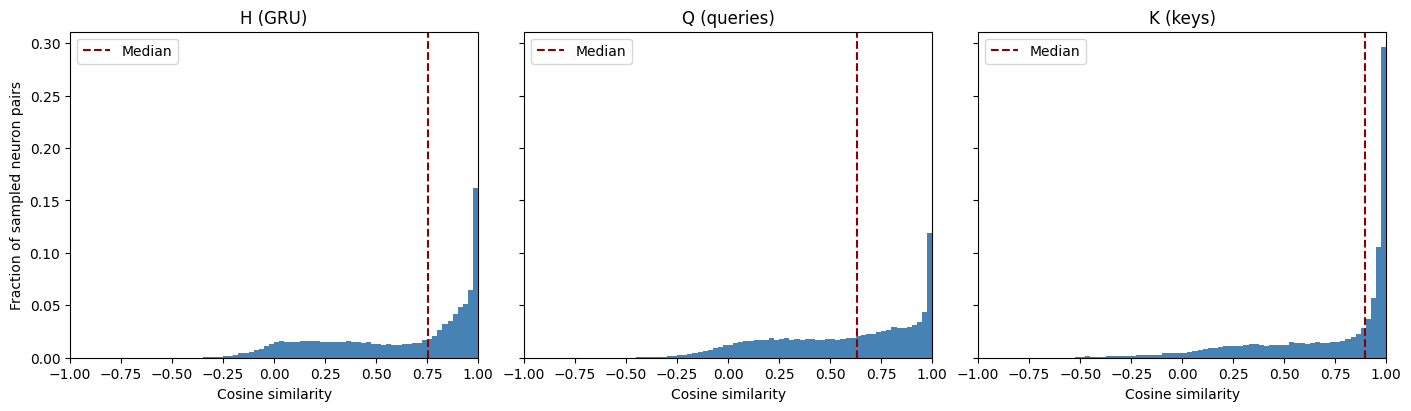

,P10,median,P90,> 0.95 (%)
representation,,,,
H (GRU),0.0599,0.7519,0.9911,22.7085
Q (queries),0.0571,0.6314,0.9824,16.2951
K (keys),0.1879,0.8963,0.9979,40.1286


In [6]:
import matplotlib.pyplot as plt

hqk_indices = np.linspace(0, len(val_windows) - 1, min(32, len(val_windows)), dtype=int)
hqk_neurons = torch.tensor(np.random.default_rng(seed).choice(n_nodes, min(n_nodes, 128),
                                                            replace=False), device=device)
hqk_pairs = torch.triu_indices(len(hqk_neurons), len(hqk_neurons), offset=1, device=device)
hqk_cosine_batches = {name: [] for name in ("H (GRU)", "Q (queries)", "K (keys)")}
hqk_original_training = model.training
try:
    model.eval()
    with torch.no_grad():
        for indices in tqdm(np.array_split(hqk_indices,
                             max(1, (len(hqk_indices) + batch_size - 1) // batch_size)),
                            desc="Compare H / Q / K", unit="batch"):
            past = torch.stack([val_windows[int(i)][0] for i in indices]).to(device)
            B, T, N = past.shape
            _, hidden = model.graph_learner.encoder(past.transpose(1, 2).reshape(B * N, T, 1))
            H = hidden[0].reshape(B, N, -1)
            representations = {"H (GRU)": H, "Q (queries)": model.graph_learner.W_q(H),
                               "K (keys)": model.graph_learner.W_k(H)}
            for name, representation in representations.items():
                unit_vectors = F.normalize(representation[:, hqk_neurons], dim=-1)
                cosine = unit_vectors @ unit_vectors.transpose(-1, -2)
                hqk_cosine_batches[name].append(
                    cosine[:, hqk_pairs[0], hqk_pairs[1]].cpu().flatten())
finally:
    model.train(hqk_original_training)

hqk_cosines = {name: torch.cat(batches).clamp(-1, 1).numpy()
               for name, batches in hqk_cosine_batches.items()}
fig_hqk, axes_hqk = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True,
                                constrained_layout=True)
hqk_rows = []
for (name, values), ax in zip(hqk_cosines.items(), axes_hqk):
    ax.hist(values, bins=np.linspace(-1, 1, 81),
            weights=np.full(len(values), 1 / len(values)), color="steelblue")
    ax.axvline(float(np.median(values)), color="darkred", linestyle="--", label="Median")
    ax.set(title=name, xlabel="Cosine similarity", xlim=(-1, 1))
    ax.legend()
    hqk_rows.append({"representation": name, "P10": np.quantile(values, 0.1),
                     "median": np.median(values), "P90": np.quantile(values, 0.9),
                     "> 0.95 (%)": 100 * (values > 0.95).mean()})
axes_hqk[0].set_ylabel("Fraction of sampled neuron pairs")
plt.show()
hqk_table = pd.DataFrame(hqk_rows).set_index("representation")
display(hqk_table.round(4))
hqk_output = results_dir
hqk_output.mkdir(parents=True, exist_ok=True)
hqk_table.to_csv(hqk_output / f"{run_prefix}_h_q_k_similarity.csv")
fig_hqk.savefig(hqk_output / f"{run_prefix}_h_q_k_similarity.png", dpi=150)


## GVAR filters

Row `k=0`: own history. Rows `k>0`: graph-shifted history.


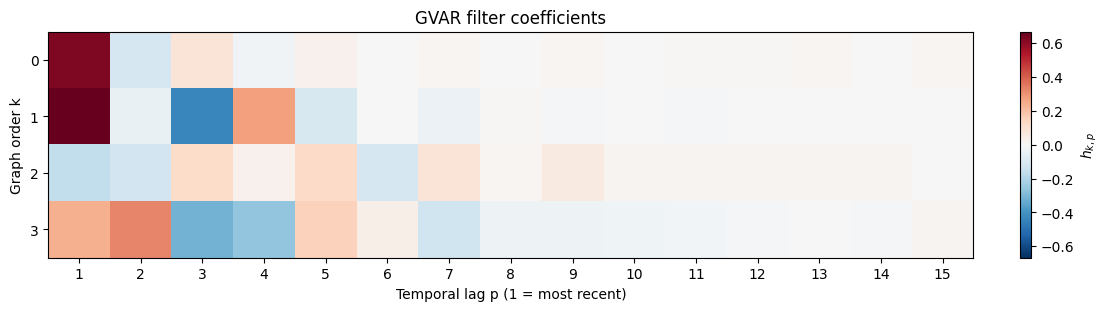

,Sum,Absolute sum
k,,
0,0.6693,0.9418
1,0.3010,1.6050
2,0.1275,0.9387
3,-0.0935,1.6371


In [7]:
h = model.h.detach().cpu().numpy()
limit = max(float(np.abs(h).max()), 1e-8)
fig_filters, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
im = ax.imshow(h, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(model.P), range(1, model.P + 1))
ax.set_yticks(range(model.K + 1))
ax.set(xlabel="Temporal lag p (1 = most recent)", ylabel="Graph order k", title="GVAR filter coefficients")
ax.grid(False)
fig_filters.colorbar(im, ax=ax, label=r"$h_{k,p}$")
plt.show()
filter_summary = pd.DataFrame({"Sum": h.sum(1), "Absolute sum": np.abs(h).sum(1)},
                              index=pd.Index(range(model.K + 1), name="k"))
display(filter_summary.round(4))
fig_filters.savefig(results_dir / f"{run_prefix}_gvar_filters.png", dpi=150)
